In [1]:
import numpy as np
import scipy.integrate as sp
import matplotlib.pyplot as plt
from Rate_laws import *

In [2]:
lower_bound = 0
upper_bound = 10
number_point = 10

In [3]:
# S1 = np.linspace(lower_bound, upper_bound, number_point)
# S2 = np.linspace(lower_bound, upper_bound, number_point)
S3 = np.linspace(lower_bound, upper_bound, number_point)
# S4 = np.linspace(lower_bound, upper_bound, number_point)

#compounds = np.array([S1, S2, S3, S4])
#compounds

In [4]:
#Default parameters for the model.


par = {
    "k1": 1.0,
    "k2": 1.0,
    "k3": 1.0,
    "alpha": 1.0,
    "beta": 1.0,
    "gamma": 1.0,
    "V1": 1.0,
    "V2": 1.0,
    "V3": 1.0,
    "V4": 1.0,
    "V5": 1.0,
    "Km1": 1.0,
    "Km2": 1.0,
    "Km3": 1.0,
    "Km4": 1.0,
    "Km5": 1.0,
    "q1": 1.0,
    "q4": 1.0,
    "y0": 1.0
}

In [5]:
compounds = ["Acetyl_CoA", "Malonyl_CoA", "Fatty_Acyl", "TAG"]

n_compounds = len(compounds)

def get_rates(y, par):
    Acetyl_CoA, Malonyl_CoA, Fatty_Acyl, TAG = y
    return {
        "v_in_1":
        constant_influx(par["k1"]),
        "v_in_2":
        constant_influx(par["k2"]),

        #"v_in_3": constant_influx(par["Kin3"]),
        "v_in_3":
        constant_influx(par["k3"]),
        "r1":
        non_competitive_inhibition(par["V1"], par["Km1"], par["q1"],
                                   Acetyl_CoA, Fatty_Acyl),
        "r2":
        michaelis_meten(par["V2"], par["Km2"], Malonyl_CoA),
        "r3":
        michaelis_meten(par["V3"], par["Km3"], Fatty_Acyl),
        "r4":
        non_competitive_inhibition(par["V4"], par["Km4"], par["q4"],
                                   Fatty_Acyl, Malonyl_CoA),
        "r5":
        michaelis_meten(par["V5"], par["Km5"], TAG),
        "v_out1":
        mass_action_law(par["alpha"], Acetyl_CoA),
        "v_out2":
        mass_action_law(par["beta"], Fatty_Acyl),
        "v_out3":
        mass_action_law(par["gamma"], TAG),
    }


############################################## Marvin #####################################################################


def model(time, y, par):
    rates = get_rates(y=y, par=par)
    d_Acetyl_CoA_dt = (rates["v_in_1"] - rates["r1"] + rates["r4"] -
                       rates["v_out1"])
    d_Malony_CoA = rates["r1"] - rates["r2"]

    d_Fatty_Acyl = (rates["v_in_2"] + rates["r2"] - rates["r3"] - rates["r4"] +
                    rates["r5"] - rates["v_out2"])

    d_TAG_dt = rates["v_in_3"] + rates["r3"] - rates["r5"] - rates["v_out3"]

    return np.array([d_Acetyl_CoA_dt, d_Malony_CoA, d_Fatty_Acyl, d_TAG_dt])


######################### Initial conditions + time points ################################################################

y0= np.zeros(n_compounds)
y0[0] = par["y0"]

time = np.linspace(0, 10, 100)
y = sp.odeint(func=model, y0=y0, t=time, args=(par, ), tfirst=True)

# Take a look at these results first, before you run the steady state simulation

########################## Plot the solutions #################################################################################

# plt.style.use('ggplot')
# fig, ax = plt.subplots()
# ax.plot(time, y)
# plt.xlabel("Time (a.u.) ")
# plt.ylabel("Concemtration (a.u.) ")
# plt.title("Concentrations over time ")
# ax.legend(compounds,
#           loc="upper left",
#           bbox_to_anchor=(1.1, 1),
#           borderaxespad=0)
# plt.tight_layout()
# plt.savefig("Concentrations.png", bbox_inches='tight')
# plt.show()

######################## Simulate the steady-state function as function of parameters#############################################
def simulate_steady_state(model, y0, par, dt=1e-3, error=1e-5, max_steps=1e8):
    r = sp.ode(model)
    r.set_integrator("lsoda", method="bdf")
    r.set_f_params(par)
    r.set_initial_value(y0, 0.0)

    y1 = y0.copy()
    nsteps = 0
    while r.successful and nsteps < max_steps:
        y2 = r.integrate(r.t + dt)
        if np.linalg.norm(y1 - y2, ord=2) < error:
            return y2
        else:
            y1 = y2
        nsteps += 1
    raise ValueError("Maximal simulation steps exceeded")
steady =  list(simulate_steady_state(model,y0, par, dt=100))
    

# A= np.linspace(0,3.6,100)
# C= []
# B= []



#for i in A:

 #   par["Kin1"]=i
  #  B.append(simulate_steady_state(model,y0, par, dt=100))

#simulate_steady_state(model)

#print(B)


#plt.style.use('ggplot')
#plt.plot(A,B)
#plt.xlabel("steady-state concentration (a.u.)")
#plt.ylabel("Metabolite oncemtrations(a.u.) ")
#plt.legend(compounds, loc="upper left", bbox_to_anchor=(1.1, 1), borderaxespad=0)
#plt.tight_layout()
#plt.savefig("Steady_state.png", bbox_inches='tight')

#plt.show()
#y_ss = simulate_steady_state(model, y0, par, dt=100)
#print(y_ss, par["Kin1"])


In [6]:
S1 = steady[0]
S2 = steady[1]
S4 = steady[3]

In [7]:
#To ind the value of S1 (Acetyl-CoA) at the steady state, we most solve  a second order polynomial 
#P2 with the coeffifcients A1, B1, C1 described below:

A1 = (par["Km4"] * S2 * S3 * par["alpha"] * (par["q1"]**2) +
      par["Km4"] * S2 * par["alpha"] * par["q1"] +
      par["Km4"] * S3 * par["alpha"] * par["q1"] + par["Km4"] * par["alpha"] +
      S2 * (S3**2) * par["alpha"] * (par["q1"]**2) +
      S2 * S3 * par["alpha"] * par["q1"] + (S3**2) * par["alpha"] * par["q1"] +
      S3 * par["alpha"])

B1 = (par["Km1"] * par["Km4"] * S2 * S3 * par["alpha"] * (par["q1"]**2) +
      par["Km1"] * par["Km4"] * S2 * par["alpha"] * par["q1"] +
      par["Km1"] * par["Km4"] * S3 * par["alpha"] * par["q1"] +
      par["Km1"] * par["Km4"] * par["alpha"] + par["Km1"] * S2 *
      (S3**2) * par["alpha"] * (par["q1"]**2) +
      par["Km1"] * S2 * S3 * par["alpha"] * par["q1"] + par["Km1"] *
      (S3**2) * par["alpha"] * par["q1"] + par["Km1"] * S3 * par["alpha"] -
      par["Km4"] * S2 * S3 * par["k1"] * (par["q1"]**2) +
      par["Km4"] * S2 * par["V1"] * par["q1"] -
      par["Km4"] * S2 * par["k1"] * par["q1"] -
      par["Km4"] * S3 * par["k1"] * par["q1"] + par["Km4"] * par["V1"] -
      par["Km4"] * par["k1"] - S2 * (S3**2) * par["k1"] * (par["q1"]**2) +
      S2 * S3 * par["V1"] * par["q1"] - S2 * S3 * par["V1"] * par["q1"] -
      (S3**2) * par["V4"] * par["q1"] - (S3**2) * par["k1"] * par["q1"] +
      S3 * par["V1"] - S3 * par["V4"] - S3 * par["k1"])

C1 = (-par["Km1"] * par["Km4"] * S1 * S3 * par["k1"] * (par["q1"]**2) -
      par["Km1"] * par["Km4"] * S2 * par["k1"] * par["q1"] -
      par["Km1"] * par["Km4"] * S3 * par["k1"] * par["q1"] -
      par["Km1"] * par["Km4"] * par["k1"] - par["Km1"] * S2 *
      (S3**2) * par["k1"] * (par["q1"]**2) -
      par["Km1"] * S2 * S3 * par["k1"] * par["q1"] - par["Km1"] *
      (S3**2) * par["V4"] * par["q1"] - par["Km1"] *
      (S3**2) * par["V4"] * par["q1"] - par["Km1"] *
      (S3**2) * par["k1"] * par["q1"] - par["Km1"] * S3 * par["V4"] -
      par["Km1"] * S3 * par["k1"])

In [8]:
#To find the value of S3 (Fatty acid ) at the steady state, we most solve  a third order polynomial 
#P2 with the coeffifcients A2, B2, C2, D2 described below:


A2 = (-par["Km2"] * par["Km5"] * S2 * par["beta"] * par["q4"] -
      par["Km2"] * par["Km5"] * par["beta"] -
      par["Km2"] * S2 * S4 * par["beta"] * par["q4"] -
      par["Km2"] * S4 * par["beta"] - par["Km5"] *
      (S2**2) * par["beta"] * par["q4"] - par["Km5"] * S2 * par["beta"] -
      (S2**2) * S4 * par["beta"] * par["q4"] - S2 * S4 * par["beta"])

B2 = (-par["Km2"] * par["Km3"] * par["Km5"] * S2 * par["beta"] * par["q4"] -
      par["Km2"] * par["Km3"] * par["Km5"] * par["beta"] -
      par["Km2"] * par["Km3"] * S4 * par["beta"] -
      par["Km2"] * par["Km4"] * par["Km5"] * S2 * par["beta"] * par["q4"] -
      par["Km2"] * par["Km4"] * par["Km5"] * par["beta"] -
      par["Km2"] * par["Km4"] * S2 * S4 * par["beta"] * par["q4"] -
      par["Km2"] * par["Km4"] * S4 * par["beta"] -
      par["Km2"] * par["Km5"] * S2 * par["V3"] * par["q4"] +
      par["Km2"] * par["Km5"] * S2 * par["k2"] * par["q4"] -
      2 * par["Km2"] * par["Km5"] * par["V3"] +
      par["Km2"] * par["Km5"] * par["k2"] -
      par["Km2"] * S2 * S4 * par["V3"] * par["q4"] +
      par["Km2"] * S2 * S4 * par["V5"] * par["q4"] +
      par["Km2"] * S2 * S4 * par["k2"] * par["q4"] -
      2 * par["Km2"] * S4 * par["V3"] + par["Km2"] * S4 * par["V5"] +
      par["Km2"] * S4 * par["k2"] - par["Km3"] * par["Km5"] *
      (S2**2) * par["beta"] * par["q4"] -
      par["Km3"] * par["Km5"] * S2 * par["beta"] - par["Km3"] *
      (S2**2) * S4 * par["beta"] * par["q4"] -
      par["Km3"] * S2 * S4 * par["beta"] - par["Km4"] * par["Km5"] *
      (S2**2) * par["beta"] * par["q4"] - par["Km5"] *
      (S2**2) * par["V3"] * par["q4"] -
      par["Km4"] * par["Km5"] * S2 * par["beta"] - par["Km4"] *
      (S2**2) * S4 * par["beta"] * par["q4"] -
      -par["Km4"] * S2 * S4 * par["beta"] + par["Km5"] *
      (S2**2) * par["V2"] * par["q4"] - par["Km5"] *
      (S2**2) * par["V3"] * par["q4"] + par["Km5"] *
      (S2**2) * par["k2"] * par["q4"] + par["Km5"] * S2 * par["V2"] -
      2 * par["Km5"] * S2 * par["V3"] + par["Km5"] * S2 * par["k2"] +
      (S2**2) * S4 * par["V2"] * par["q4"] -
      (S2**2) * S4 * par["V3"] * par["q4"] +
      (S2**2) * S4 * par["V5"] * par["q4"] +
      (S2**2) * S4 * par["k2"] * par["q4"] + S2 * S4 * par["V2"] -
      2 * S2 * S4 * par["V3"] + S2 * S4 * par["V5"] + S2 * S4 * par["k2"])

C2 = (
    -par["Km2"] * par["Km3"] * par["Km4"] * par["Km5"] * S2 * par["beta"] *
    par["q4"] -
    par["Km2"] * par["Km3"] * par["Km4"] * par["Km5"] * par["beta"] -
    par["Km2"] * par["Km3"] * par["Km4"] * S2 * S4 * par["beta"] * par["q4"] -
    par["Km2"] * par["Km3"] * par["Km4"] * S4 * par["beta"] +
    par["Km2"] * par["Km3"] * par["Km5"] * S2 * par["k2"] * par["q4"] -
    par["Km2"] * par["Km3"] * par["Km5"] * par["V3"] +
    par["Km2"] * par["Km3"] * par["Km5"] * par["k2"] +
    par["Km2"] * par["Km3"] * S2 * S4 * par["V5"] * par["q4"] +
    par["Km2"] * par["Km3"] * S2 * S4 * par["k2"] * par["q4"] -
    par["Km2"] * par["Km3"] * S4 * par["V3"] +
    par["Km2"] * par["Km3"] * S4 * par["V5"] +
    par["Km2"] * par["Km3"] * S4 * par["k2"] -
    par["Km2"] * par["Km4"] * par["Km5"] * S2 * par["V3"] * par["q4"] +
    par["Km2"] * par["Km4"] * par["Km5"] * S2 * par["k2"] * par["q4"] -
    par["Km2"] * par["Km4"] * par["Km5"] * par["V3"] +
    par["Km2"] * par["Km4"] * par["Km5"] * par["k2"] -
    par["Km2"] * par["Km4"] * S2 * S4 * par["V3"] * par["q4"] +
    par["Km2"] * par["Km4"] * S2 * S4 * par["V5"] * par["q4"] +
    par["Km2"] * par["Km4"] * S2 * S4 * par["k2"] * par["q4"] -
    par["Km2"] * par["Km4"] * S4 * par["V3"] +
    par["Km2"] * par["Km4"] * S4 * par["V5"] +
    par["Km2"] * par["Km4"] * S4 * par["k2"] -
    par["Km3"] * par["Km4"] * par["Km5"] * (S2**2) * par["beta"] * par["q4"] -
    par["Km3"] * par["Km4"] * par["Km5"] * S2 * par["beta"] -
    par["Km3"] * par["Km4"] * (S2**2) * S4 * par["beta"] * par["q4"] -
    par["Km3"] * par["Km4"] * S2 * S4 * par["beta"] + par["Km3"] * par["Km5"] *
    (S2**2) * par["V2"] * par["q4"] + par["Km3"] * par["Km5"] *
    (S2**2) * par["k2"] * par["q4"] +
    par["Km3"] * par["Km5"] * S2 * par["V2"] -
    par["Km3"] * par["Km5"] * S2 * par["V3"] +
    par["Km3"] * par["Km5"] * S2 * par["k2"] + par["Km3"] *
    (S2**2) * S4 * par["V2"] * par["q4"] + par["Km3"] *
    (S2**2) * S4 * par["V5"] * par["q4"] + par["Km3"] *
    (S2**2) * S4 * par["k2"] * par["q4"] + par["Km3"] * S2 * S4 * par["V2"] -
    par["Km3"] * S2 * S4 * par["V3"] + par["Km3"] * S2 * S4 * par["V5"] +
    par["Km3"] * S2 * S4 * par["k2"] + par["Km4"] * par["Km5"] *
    (S2**2) * par["V2"] * par["q4"] - par["Km4"] * par["Km5"] *
    (S2**2) * par["V3"] * par["q4"] + par["Km4"] * par["Km5"] *
    (S2**2) * par["k2"] * par["q4"] +
    par["Km4"] * par["Km5"] * S2 * par["V2"] -
    par["Km4"] * par["Km5"] * S2 * par["V3"] +
    par["Km4"] * par["Km5"] * S2 * par["k2"] + par["Km4"] *
    (S2**2) * S4 * par["V2"] * par["q4"] - par["Km4"] *
    (S2**2) * S4 * par["V3"] * par["q4"] + par["Km4"] *
    (S2**2) * S4 * par["V5"] * par["q4"] + par["Km4"] *
    (S2**2) * S4 * par["k2"] * par["q4"] + par["Km4"] * S2 * S4 * par["V2"] -
    par["Km4"] * S2 * S4 * par["V3"] + par["Km4"] * S2 * S4 * par["V5"] +
    par["Km4"] * S2 * S4 * par["k2"])

D2 = (par["Km2"] * par["Km3"] * par["Km4"] * par["Km5"] * S2 * par["k2"] *
      par["q4"] +
      par["Km2"] * par["Km3"] * par["Km4"] * par["Km5"] * par["k2"] +
      par["Km2"] * par["Km3"] * par["Km4"] * S2 * S4 * par["V5"] * par["q4"] +
      par["Km2"] * par["Km3"] * par["Km4"] * S2 * S4 * par["k2"] * par["q4"] +
      par["Km2"] * par["Km3"] * par["Km4"] * S4 * par["V5"] +
      par["Km2"] * par["Km3"] * par["Km4"] * S4 * par["k2"] +
      par["Km3"] * par["Km4"] * par["Km5"] * (S2**2) * par["V2"] * par["q4"] +
      par["Km3"] * par["Km4"] * par["Km5"] * (S2**2) * par["k2"] * par["q4"] +
      par["Km3"] * par["Km4"] * par["Km5"] * S2 * par["V2"] +
      par["Km3"] * par["Km4"] * par["Km5"] * S2 * par["k2"] +
      par["Km3"] * par["Km4"] * (S2**2) * S4 * par["V2"] * par["q4"] +
      par["Km3"] * par["Km4"] * (S2**2) * S4 * par["V5"] * par["q4"] +
      par["Km3"] * par["Km4"] * (S2**2) * S4 * par["k2"] * par["q4"] +
      par["Km3"] * par["Km4"] * S2 * S4 * par["V2"] +
      par["Km3"] * par["Km4"] * S2 * S4 * par["V5"] +
      +par["Km3"] * par["Km4"] * S2 * S4 * par["k2"])

In [9]:
#To find the value of S4 (Triglycerides) at the steady state, we most solve  a second order polynomial 
#P3 with the coeffifcients A3, B3, C3 described below:

A3 = -par["Km3"] * par["gamma"] - S3 * par["gamma"]
B3 = (-par["Km3"] * par["Km5"] * par["gamma"] - par["Km3"] * par["V5"] +
      par["Km3"] * par["k3"] - par["Km3"] * S3 * par["gamma"] +
      S3 * par["V3"] - S3 * par["V5"] + S3 * par["k3"])
C3 = par["Km3"]*par["Km5"]*par["k3"] + par["Km5"]*S3*par["V3"] + par["Km5"]*S3*par["k3"]

In [10]:
print(C3)

[ 1.          3.22222222  5.44444444  7.66666667  9.88888889 12.11111111
 14.33333333 16.55555556 18.77777778 21.        ]


In [11]:
def polynome_1(S1, par):

    exp = A1*S1**2 + B1*S1 +C1
    return exp

In [12]:
def discriminant(a, b, c):
    exp = b**2 - 4*a*c
    return exp

In [13]:
S1_steady = (-B1 + np.sqrt(discriminant(A1, B1, C1)))/(2*A1)
S2_steady = (par["V1"]*par["Km2"]*S1)/(par["V2"]*par["Km1"]*par["q1"]*S3 + par["V2"]*par["Km1"] + par["V2"]*par["q1"]*S1*S3 + (par["V2"]-par["V1"])*S1)
#S3_steady = pass
S4_steady = (-B3 - np.sqrt(discriminant(A3, B3, C3)))/(2*A3)

In [14]:
print(S1_steady)

[0.61803399 1.26665095 1.50133487 1.6198672  1.69116013 1.73872037
 1.77269583 1.79817536 1.81798981 1.83383869]


In [15]:
print(S2_steady)

[1.08310503 0.32677178 0.192411   0.13634796 0.10558386 0.08614664
 0.0727533  0.06296416 0.05549692 0.04961305]


In [16]:
print(S4_steady)

[0.61803399 1.02109667 1.15392409 1.219735   1.25900023 1.28507922
 1.30365752 1.31756357 1.32836275 1.33699148]


In [17]:
y = polynome_1(S3,par)

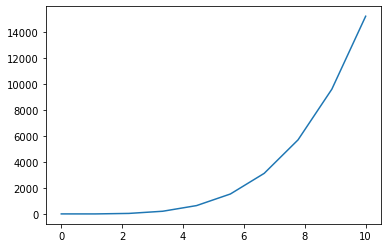

In [18]:
plt.plot(S3, y)

In [19]:
def polynome_2(par, S3):
    exp = A2 * S3**3 + B2 * S3**2 + C2 * S3 + D2
    return exp

In [20]:
def deriv_polynome_2(par, S3):
    exp = 3 * A2 * S3**2 + 2 * B2 * S3 + C2
    return exp

In [21]:
def polynome_2(par, S3):
    exp = A3 * S3**3 + B3 * S3**2 + C3 * S3 + D2
    return exp

In [22]:
def delta_deriv_polynome_2(a, b, c):
    exp = b**2 - 3 * a * c
    return exp


x1 = (-B2 + np.sqrt(delta_deriv_polynome_2(A2, B2, C2))) / 3 * A2
x2 = (-B2 - np.sqrt(delta_deriv_polynome_2(A2, B2, C2))) / 3 * A2
x1

-18.50807464269284

In [23]:
def polynome_4(par,S4):
    exp = A4*S4**2 + B4*S4 +C4
    return exp


In [24]:
polynome_2(par, x2)

array([ -19.23429123,  -36.39213191,  -53.5499726 ,  -70.70781328,
        -87.86565396, -105.02349464, -122.18133532, -139.339176  ,
       -156.49701668, -173.65485736])